# Бустинг: предсказываем зарплату в USD

**Тип задачи:** регрессия (предсказываем число, а не класс).
**Цель:** `salary_in_usd`.

План, по которому решается почти любая табличная ML-задача:
1. Загрузить и посмотреть данные
2. Найти ловушки (утечки, дубли, пропуски, мусор)
3. Решить, какие признаки даём модели
4. Разбить данные на train / valid / test
5. Построить бейзлайн — «тупую» модель, с которой сравниваемся
6. Обучить бустинг
7. Оценить на test и понять, что модель выучила

## 1. Загрузка и первый взгляд

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

df = pd.read_csv('/Users/bolshiedengi/Downloads/data_boosting.csv')
print(df.shape)
df.head()

(3755, 11)


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,80000,EUR,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,USD,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,USD,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,USD,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,USD,120000,CA,100,CA,M


In [2]:
# Типы колонок и пропуски
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3755 entries, 0 to 3754
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           3755 non-null   int64 
 1   experience_level    3755 non-null   object
 2   employment_type     3755 non-null   object
 3   job_title           3755 non-null   object
 4   salary              3755 non-null   int64 
 5   salary_currency     3755 non-null   object
 6   salary_in_usd       3755 non-null   int64 
 7   employee_residence  3755 non-null   object
 8   remote_ratio        3755 non-null   int64 
 9   company_location    3755 non-null   object
 10  company_size        3755 non-null   object
dtypes: int64(4), object(7)
memory usage: 322.8+ KB


In [3]:
# Сколько уникальных значений в каждой колонке.
# Мало уникальных — категория (S/M/L), много — либо число, либо «широкая» категория (job_title).
df.nunique()

work_year                4
experience_level         4
employment_type          4
job_title               93
salary                 815
salary_currency         20
salary_in_usd         1035
employee_residence      78
remote_ratio             3
company_location        72
company_size             3
dtype: int64

count      3755.000000
mean     137570.389880
std       63055.625278
min        5132.000000
25%       95000.000000
50%      135000.000000
75%      175000.000000
max      450000.000000
Name: salary_in_usd, dtype: float64


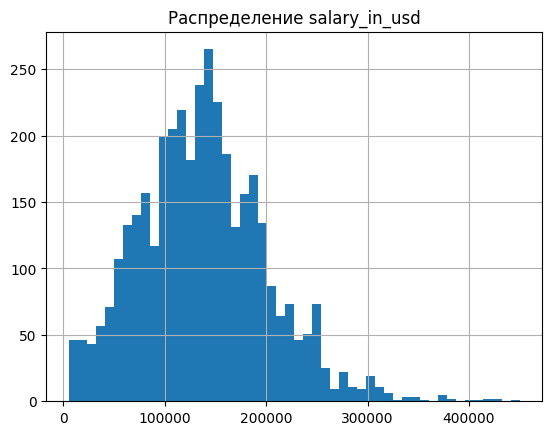

In [4]:
# Смотрим на цель: разброс, выбросы
print(df['salary_in_usd'].describe())
df['salary_in_usd'].hist(bins=50)
plt.title('Распределение salary_in_usd'); plt.show()

Зарплата медианно ~135k, но есть хвост до 450k. Запомним: **std ≈ 63k** — это примерно та ошибка, которую мы получим, если всегда предсказывать среднее.

In [5]:
# Как цель зависит от опыта — проверяем здравый смысл
df.groupby('experience_level')['salary_in_usd'].median().sort_values()

experience_level
EN     70000.0
MI    100000.0
SE    146000.0
EX    196000.0
Name: salary_in_usd, dtype: float64

EN < MI < SE < EX — логично. Значит в признаках есть сигнал.

## 2. Ловушки

### 2.1 Утечка целевой переменной (target leakage) — САМОЕ ВАЖНОЕ В ЭТОЙ ЗАДАЧЕ

Колонка `salary` — это та же зарплата, только в местной валюте. `salary` + `salary_currency` → `salary_in_usd` считается простым умножением на курс.
Если оставить их, модель «предскажет» зарплату идеально, но это обман: в реальной жизни, когда нам нужно предсказать зарплату, мы её **ещё не знаем**.

Вопрос, который задаём про каждый признак: **«будет ли он известен в момент, когда нужен прогноз?»** Если нет — выкидываем.

In [6]:
# Доказываем: для USD-зарплат salary == salary_in_usd
usd = df[df['salary_currency'] == 'USD']
print('Доля USD-строк, где salary == salary_in_usd:', (usd['salary'] == usd['salary_in_usd']).mean())

Доля USD-строк, где salary == salary_in_usd: 1.0


### 2.2 Дубликаты

In [7]:
print('Полных дублей строк:', df.duplicated().sum(), 'из', len(df))

Полных дублей строк: 1171 из 3755


Почти треть строк — точные копии. Это может быть нормально (много людей «SE, Data Scientist, US, 150000»), ID-шника у нас нет, так что отличить нельзя.

Почему это важно: если копия строки попала и в train, и в test — модель на test «видит знакомое», и оценка получается чуть завышенной. Я **оставляю** дубли (это реальные разные люди, скорее всего), но держим в голове, что метрика немного оптимистична. В конце проверим, насколько.

## 3. Признаки

- **Выкидываем:** `salary`, `salary_currency` (утечка), `salary_in_usd` (это цель).
- **Числовые:** `work_year`, `remote_ratio`.
- **Категориальные:** всё остальное (строки).

Модели работают с числами, поэтому строки обычно надо кодировать (one-hot и т.п.). Мы берём **CatBoost** — он умеет принимать категории как есть, нужно только сказать, какие колонки категориальные. Для новичка это самый безболезненный бустинг.

In [8]:
target = 'salary_in_usd'
cat_features = ['experience_level', 'employment_type', 'job_title',
                'employee_residence', 'company_location', 'company_size']
num_features = ['work_year', 'remote_ratio']
features = num_features + cat_features

X = df[features]
y = df[target]
X.head()

,work_year,remote_ratio,experience_level,employment_type,job_title,employee_residence,company_location,company_size
0,2023,100,SE,FT,Principal Data Scientist,ES,ES,L
1,2023,100,MI,CT,ML Engineer,US,US,S
2,2023,100,MI,CT,ML Engineer,US,US,S
3,2023,100,SE,FT,Data Scientist,CA,CA,M
4,2023,100,SE,FT,Data Scientist,CA,CA,M


## 4. Разбиение: train / valid / test

- **train (60%)** — на нём модель учится.
- **valid (20%)** — по нему решаем, когда остановить обучение и какие гиперпараметры лучше.
- **test (20%)** — смотрим **один раз в самом конце**. Это «экзамен».

Почему не просто train/test? Если подбирать параметры, глядя на test, мы подгоняем модель под test, и его оценка перестаёт быть честной. `random_state=42` — чтобы разбиение было одинаковым при каждом запуске.

In [9]:
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, random_state=42)  # 0.25*0.8 = 0.2
print(len(X_train), len(X_val), len(X_test))

2253 751 751


## 5. Метрики и бейзлайн

- **MAE** — средняя ошибка в долларах. Самая понятная: «в среднем промахиваемся на N$».
- **RMSE** — как MAE, но сильнее штрафует большие промахи.
- **R²** — доля разброса, которую объяснила модель. 0 = не лучше среднего, 1 = идеально.

**Бейзлайн** — предсказывать всем среднюю зарплату из train. Без него цифра «MAE = 37k» ничего не значит: хорошо это или плохо?

In [10]:
def report(name, y_true, y_pred):
    return {'model': name,
            'MAE': round(mean_absolute_error(y_true, y_pred)),
            'RMSE': round(mean_squared_error(y_true, y_pred) ** 0.5),
            'R2': round(r2_score(y_true, y_pred), 3)}

baseline_pred = np.full(len(y_test), y_train.mean())
results = [report('Бейзлайн: среднее', y_test, baseline_pred)]
pd.DataFrame(results)

,model,MAE,RMSE,R2
0,Бейзлайн: среднее,48845,62859,-0.001


## 6. Бустинг

Напоминание, что происходит внутри: строится дерево → смотрим, где оно ошиблось (остатки) → следующее дерево учится исправлять эти ошибки → и так сотни раз. Каждое дерево добавляется с маленьким весом (`learning_rate`).

Главные параметры:
- `iterations` — максимум деревьев;
- `learning_rate` — насколько сильно каждое дерево влияет. Меньше → нужно больше деревьев, но обычно точнее;
- `depth` — глубина каждого дерева (сложность одного «шага»);
- **early stopping** — смотрим ошибку на valid после каждого дерева и останавливаемся, когда она перестала падать. Это главная защита от переобучения.

In [11]:
model = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.05,
    depth=6,
    loss_function='RMSE',
    cat_features=cat_features,
    random_seed=42,
    verbose=200,
)
model.fit(X_train, y_train,
          eval_set=(X_val, y_val),
          early_stopping_rounds=100,   # 100 деревьев без улучшения на valid → стоп
          use_best_model=True)
print('Лучшее число деревьев:', model.get_best_iteration())

0:	learn: 62235.4899085	test: 61770.8794989	best: 61770.8794989 (0)	total: 58.2ms	remaining: 1m 56s


200:	learn: 44727.3127583	test: 49028.6257977	best: 48954.5553236 (145)	total: 304ms	remaining: 2.72s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 48954.55532
bestIteration = 145

Shrink model to first 146 iterations.
Лучшее число деревьев: 145


### Кривая обучения — как увидеть переобучение глазами
Ошибка на train падает всегда (модель запоминает данные). Ошибка на valid сначала падает, потом перестаёт или растёт — с этого момента модель зубрит, а не учится.

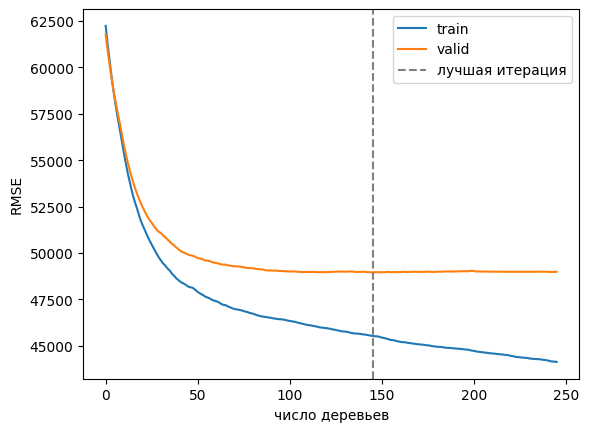

In [12]:
ev = model.get_evals_result()
plt.plot(ev['learn']['RMSE'], label='train')
plt.plot(ev['validation']['RMSE'], label='valid')
plt.axvline(model.get_best_iteration(), color='gray', ls='--', label='лучшая итерация')
plt.xlabel('число деревьев'); plt.ylabel('RMSE'); plt.legend(); plt.show()

## 7. Оценка на test (экзамен)

In [13]:
test_pred = model.predict(X_test)
results.append(report('CatBoost', y_test, test_pred))
train_res = report('CatBoost на train (для сравнения)', y_train, model.predict(X_train))
pd.DataFrame(results + [train_res])

,model,MAE,RMSE,R2
0,Бейзлайн: среднее,48845,62859,-0.001
1,CatBoost,37726,48741,0.398
2,CatBoost на train (для сравнения),34494,45702,0.478


Как читать:
- Сравниваем с бейзлайном: насколько MAE упала → модель реально что-то выучила.
- Сравниваем train и test: если на train сильно лучше — есть переобучение. Небольшой разрыв нормален.
- R² ≈ 0.4 — модель объясняет ~40% разброса зарплат. Мало? Для этих данных — нормально: у нас нет навыков, компании, стажа в годах, города. Два «Senior Data Scientist в US» могут получать 120k и 300k, и по нашим колонкам их не отличить.

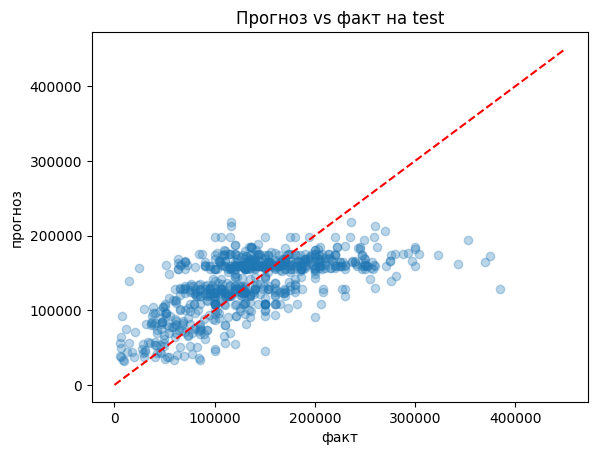

In [14]:
# Предсказание vs факт: идеальная модель — точки на диагонали
plt.scatter(y_test, test_pred, alpha=0.3)
lim = [0, y.max()]
plt.plot(lim, lim, 'r--')
plt.xlabel('факт'); plt.ylabel('прогноз'); plt.title('Прогноз vs факт на test'); plt.show()

Видно типичное поведение регрессии на шумных данных: модель «стягивает» прогнозы к середине — низкие зарплаты переоценивает, высокие недооценивает.

### Что модель считает важным

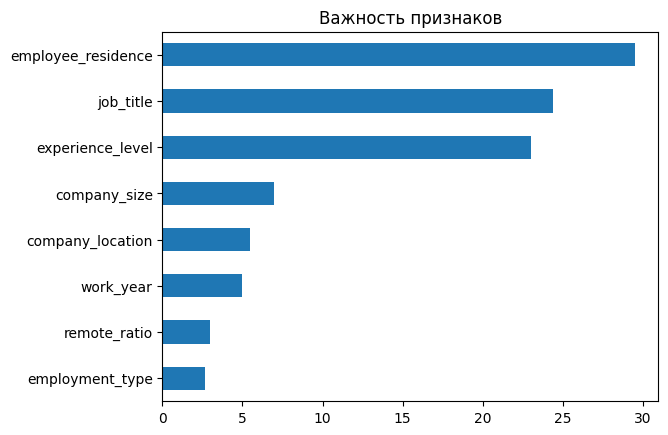

employee_residence    29.516338
job_title             24.403027
experience_level      23.040067
company_size           6.970659
company_location       5.445813
work_year              4.979014
remote_ratio           2.964840
employment_type        2.680242
dtype: float64

In [15]:
imp = pd.Series(model.get_feature_importance(), index=features).sort_values()
imp.plot.barh(); plt.title('Важность признаков'); plt.show()
imp.sort_values(ascending=False)

## 8. Проверка для понимания: что было бы с утечкой

Обучим ту же модель, но оставим `salary` и `salary_currency`. Это **не решение**, а демонстрация, почему так делать нельзя.

In [16]:
leak_feats = features + ['salary', 'salary_currency']
Xl = df[leak_feats]
Xl_trval, Xl_test, _, _ = train_test_split(Xl, y, test_size=0.2, random_state=42)
Xl_train, Xl_val, _, _ = train_test_split(Xl_trval, y_trval, test_size=0.25, random_state=42)
leak = CatBoostRegressor(iterations=2000, learning_rate=0.05, depth=6, random_seed=42, verbose=0,
                         cat_features=cat_features + ['salary_currency'])
leak.fit(Xl_train, y_train, eval_set=(Xl_val, y_val), early_stopping_rounds=100)
pd.DataFrame(results + [report('С УТЕЧКОЙ (так нельзя)', y_test, leak.predict(Xl_test))])

,model,MAE,RMSE,R2
0,Бейзлайн: среднее,48845,62859,-0.001
1,CatBoost,37726,48741,0.398
2,С УТЕЧКОЙ (так нельзя),2218,5367,0.993


R² около 0.99 — подозрительно хорошо. **Правило: если метрика слишком хорошая — ищи утечку, а не радуйся.**

## 9. Проверка влияния дублей

In [17]:
d = df.drop_duplicates()
Xd, yd = d[features], d[target]
Xd_trval, Xd_test, yd_trval, yd_test = train_test_split(Xd, yd, test_size=0.2, random_state=42)
Xd_train, Xd_val, yd_train, yd_val = train_test_split(Xd_trval, yd_trval, test_size=0.25, random_state=42)
md_ = CatBoostRegressor(iterations=2000, learning_rate=0.05, depth=6, random_seed=42, verbose=0, cat_features=cat_features)
md_.fit(Xd_train, yd_train, eval_set=(Xd_val, yd_val), early_stopping_rounds=100)
pd.DataFrame([report('Бейзлайн (без дублей)', yd_test, np.full(len(yd_test), yd_train.mean())),
              report('CatBoost (без дублей)', yd_test, md_.predict(Xd_test))])

,model,MAE,RMSE,R2
0,Бейзлайн (без дублей),53719,66147,-0.000
1,CatBoost (без дублей),39387,51857,0.385


Без дублей метрики немного хуже — значит часть «качества» основной модели была за счёт повторяющихся строк. Но отрыв от бейзлайна сохраняется, то есть модель действительно учится.

## Итог

1. Задача — регрессия, цель `salary_in_usd`, метрика MAE (понятна в долларах) + RMSE и R².
2. Выкинули `salary` и `salary_currency` — это утечка цели.
3. CatBoost с категориальными признаками «как есть», early stopping по valid.
4. На test модель заметно лучше бейзлайна; R² ~0.4 ограничен самими данными, а не моделью.
5. Главные признаки — страна проживания, должность и уровень опыта.